In [77]:
import pandas as pd

df = pd.read_csv("daily-min-tem.csv")
df.columns = ["date", "temp"]

print(df.head())
print(df.shape)

         date  temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8
(3650, 2)


In [78]:
temps = df["temp"].values
temps

array([20.7, 17.9, 18.8, ..., 13.5, 15.7, 13. ], shape=(3650,))

In [79]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

temps = scaler.fit_transform(
    temps.reshape(-1, 1)
)

In [80]:
# Sequence yaratish
# [day1 ... day30]  -> day31
# [day2 ... day31]  -> day32
# [day3 ... day32]  -> day33

import numpy as np

sequence_length = 30

X = []
y = []

for i in range(len(temps) - sequence_length):

    X.append(
        temps[i:i+sequence_length]
    )

    y.append(
        temps[i+sequence_length]
    )

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(3620, 30, 1)
(3620, 1)


In [81]:
import torch
import torch.nn as nn

X = torch.tensor(
    X,
    dtype=torch.float32
)

y = torch.tensor(
    y,
    dtype=torch.float32
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [82]:
train_size = int(0.8 * len(X))

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]


In [83]:
X = X.to(device)
y = y.to(device)

In [84]:
# RNN model
# Muhim shape:
#    (batch_size,
#     sequence_length,
#     input_size)
# Bizda input_size = 1 chunki faqat temperatura ishlatyapmiz.

In [85]:
import torch.nn as nn

class TemperatureRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn1 = nn.RNN(
           input_size=1,
           hidden_size=64,
        batch_first=True,
        dropout=0.2
)

        self.rnn2 = nn.RNN(
    input_size=64,
    hidden_size=256,
    batch_first=True,
    dropout=0.3
)

        self.rnn3 = nn.RNN(
    input_size=256,
    hidden_size=128,
    batch_first=True,
    dropout=0.4
)
        self.rnn4 = nn.RNN(
    input_size=128,
    hidden_size=8,
    batch_first=True,
    dropout=0.2
)
       
        
        self.fc = nn.Linear(8, 1)
    def forward(self, x):

        output, hidden = self.rnn1(x)
        output, hidden = self.rnn2(output)
        output, hidden = self.rnn3(output)
        output, hidden = self.rnn4(output)
       

        last_output = output[:, -1, :]

        prediction = self.fc(
            last_output
        )

        return prediction

In [86]:
print(torch.cuda.is_available())

True


In [87]:
model = TemperatureRNN()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

X_train = X_train.to(device)
y_train = y_train.to(device)

/home/ibrohim/main/.venv/lib/python3.14/site-packages/torch/nn/modules/rnn.py:655: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__(mode, *args, **kwargs)
/home/ibrohim/main/.venv/lib/python3.14/site-packages/torch/nn/modules/rnn.py:655: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  super().__init__(mode, *args, **kwargs)
/home/ibrohim/main/.venv/lib/python3.14/site-packages/torch/nn/modules/rnn.py:655: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.4 and num_layers=1
  super().__init__(mode, *args, **kwargs)


In [88]:
print("Model:", next(model.parameters()).device)
print("Data:", X.device)

Model: cuda:0
Data: cuda:0


In [89]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3080 Ti Laptop GPU


In [90]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)


In [91]:
epochs = 600

criterion = nn.MSELoss()

for epoch in range(epochs):

    model.train()

    # 1. Forward propagation
    predictions = model(X_train)

    # 2. Calculate loss
    loss = criterion(predictions, y_train)

    # 3. Clear old gradients
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Gradient clipping (RNN uchun muhim)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

    # 6. Update weights
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch: {epoch + 1}/{epochs}, "
            f"Loss: {loss.item():.4f}"
        )

Epoch: 100/600, Loss: 0.0102
Epoch: 200/600, Loss: 0.0088
Epoch: 300/600, Loss: 0.0088
Epoch: 400/600, Loss: 0.0086
Epoch: 500/600, Loss: 0.0086
Epoch: 600/600, Loss: 0.0085


In [92]:
X_test = X_test.to(device)

print("Test data:", X_test.device)
print("Model:", next(model.parameters()).device)

model.eval()

with torch.no_grad():

    preds = model(X_test)

Test data: cuda:0
Model: cuda:0


In [93]:
y_test = y_test.to(device)
actual = y_test.detach().cpu().numpy()
predicted = preds.detach().cpu().numpy()

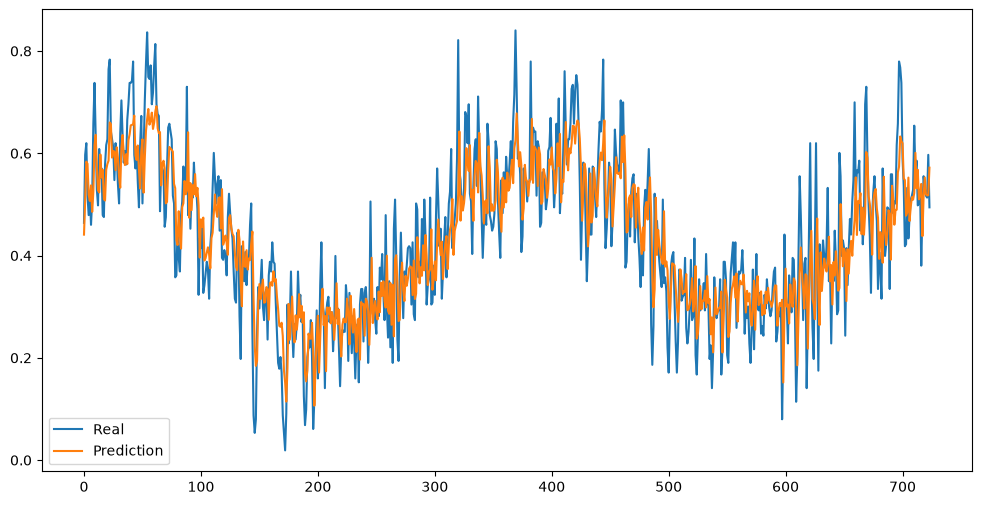

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    actual,
    label="Real"
)

plt.plot(
    predicted,
    label="Prediction"
)

plt.legend()

plt.show()